# Bank marketing response: Week 2 variation (VIP list of 5%)

**Author:** Habib Bashir Lawal

**Based on:** Dr Okunola Orogun's Cohort 2, Module 1, Week 2 notebook (UCI Bank Marketing data).

## My revised business assumption
The bank now wants only a small **VIP list of 5% of customers instead of 20%, for example because each VIP call is handled by a senior relationship manager and is expensive.
Everything else stays the same.
While `duration` is removed because it leaks the future, and the model is chosen on validation data.

## What I changed in the lecturer's notebook

| Cell | Change |
|---|---|
| 2 | `contact_capacity` from 0.20 to 0.05, new output folder, the old 0.20 kept as `original_capacity` |
| 4 | Small fix so the "unknown" count also works on pandas 3 |
| Last sections | New Part 2 (20% vs 5% and what the VIP list looks like) and Part 3 (stability across random splits) |


In [34]:
# Importing the Libraries we need

from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

In [35]:
# Settings including CONFIG, PARAMS, and SCHEMA
#   This is where my business assumption lives. I changed contact_capacity
#   from 0.20 to 0.05 because the bank now wants a small VIP list. I kept the old 0.20
#   as original_capacity so I can compare both later, and I gave the outputs a new folder

CONFIG = {
    "project_name": "bank_marketing_vip_5_percent",
    "data_file": "data/uci-bank-marketing/bank-additional-full.csv",
    "official_url": "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
    "target": "y",
    "positive_label": "yes",
    "leakage_columns": ["duration"],
    "test_size": 0.20,
    "validation_size": 0.25,  
    "random_state": 42, 
    "contact_capacity": 0.05,  # VIP list of 5% only
    "original_capacity": 0.20,  # my mentors value, kept only for the comparison in Part 2
    "selection_metric": "average_precision",
    "output_dir": "portfolio_outputs/week02_variation_vip_5_percent",  
}

PARAMS = {
    "logistic_regression": {
        "C": 1.0,
        "class_weight": "balanced",
        "max_iter": 1_000,
    },
    "random_forest": {
        "n_estimators": 250,
        "max_depth": 14,
        "min_samples_leaf": 8,
        "class_weight": "balanced_subsample",
        "n_jobs": -1,
    },
}

SCHEMA = {
    "numeric": [
        "age", "duration", "campaign", "pdays", "previous",
        "emp.var.rate", "cons.price.idx", "cons.conf.idx",
        "euribor3m", "nr.employed",
    ],
    "categorical": [
        "job", "marital", "education", "default", "housing", "loan",
        "contact", "month", "day_of_week", "poutcome",
    ],
    "target": "y",
    "allowed_target_values": {"yes", "no"},
}

OUTPUT_DIR = Path(CONFIG["output_dir"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", CONFIG["project_name"])
print("Output directory:", OUTPUT_DIR.resolve())

Project: bank_marketing_vip_5_percent
Output directory: C:\Users\HP\Desktop\Bank_Marketing-VIP_5%\portfolio_outputs\week02_variation_vip_5_percent


In [36]:
# Here is our Helper functions to find and load the data either Locally or it download it
# the functions look for the CSV on my computer and, only if 
# it is missing, then it download the official UCI zip. Then I load the file into raw_df.

def locate_local_data(relative_path: str) -> Path | None:
    candidates = [
        Path(relative_path),
        Path.cwd() / relative_path,
        Path.cwd() / "deliverables/cohort-2/module-1" / relative_path,
        Path.cwd().parent / relative_path,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    return None


def download_uci_data(url: str, destination: Path) -> Path:
    print("Local CSV not found. Downloading the official UCI archive...")
    destination.parent.mkdir(parents=True, exist_ok=True)

    with urlopen(url, timeout=60) as response:
        outer_zip = ZipFile(BytesIO(response.read()))
        nested_bytes = outer_zip.read("bank-additional.zip")

    with ZipFile(BytesIO(nested_bytes)) as nested_zip:
        csv_bytes = nested_zip.read(
            "bank-additional/bank-additional-full.csv"
        )

    destination.write_bytes(csv_bytes)
    return destination.resolve()


def ingest_data(config: dict) -> tuple[pd.DataFrame, Path]:
    data_path = locate_local_data(config["data_file"])
    if data_path is None:
        data_path = download_uci_data(
            config["official_url"], Path(config["data_file"])
        )

    frame = pd.read_csv(data_path, sep=";")
    print(f"Loaded {frame.shape[0]:,} rows and {frame.shape[1]} columns")
    print("Source file:", data_path)
    return frame, data_path


raw_df, DATA_PATH = ingest_data(CONFIG)
raw_df.head()

Loaded 41,188 rows and 21 columns
Source file: C:\Users\HP\Desktop\Bank_Marketing-VIP_5%\data\uci-bank-marketing\bank-additional-full.csv


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no


In [37]:
"""Schema validation and data quality report
   I check that every column I expect is present, that the numeric
   columns really hold numbers, and that the target only contains yes or no. Then I
   print missing values, duplicate rows and how many "unknown" answers each column has.
 My decision: I fixed one line (FIXED) so the "unknown" count also works on pandas 3, where text columns are labelled str instead
   of object. Without that fix the counts will silently show 0. So I decided to keep "unknown"
   as its own category and not delete those rows, because it is real information about
   the customer."""

def validate_schema(frame: pd.DataFrame, schema: dict) -> pd.DataFrame:
    required = schema["numeric"] + schema["categorical"] + [schema["target"]]
    missing_columns = sorted(set(required) - set(frame.columns))
    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")

    invalid_numeric = []
    for column in schema["numeric"]:
        converted = pd.to_numeric(frame[column], errors="coerce")
        if converted.isna().sum() > frame[column].isna().sum():
            invalid_numeric.append(column)
    if invalid_numeric:
        raise TypeError(f"Non-numeric values found in: {invalid_numeric}")

    target_values = set(frame[schema["target"]].dropna().unique())
    if not target_values.issubset(schema["allowed_target_values"]):
        raise ValueError(f"Unexpected target values: {target_values}")

    report = pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing_count": frame.isna().sum(),
        "missing_rate": frame.isna().mean(),
        "unique_values": frame.nunique(dropna=False),
        "unknown_count": [
            int((frame[column] == "unknown").sum())
            if not pd.api.types.is_numeric_dtype(frame[column]) else 0  # FIXED: also works on pandas 3
            for column in frame.columns
        ],
    })
    report["unknown_rate"] = report["unknown_count"] / len(frame)
    report.index.name = "column"

    print("Schema validation passed")
    print("Duplicate rows:", int(frame.duplicated().sum()))
    return report.sort_values("unknown_rate", ascending=False)


quality_report = validate_schema(raw_df, SCHEMA)
quality_report.to_csv(OUTPUT_DIR / "data_quality_report.csv")
quality_report.head(12)

Schema validation passed
Duplicate rows: 12


,dtype,missing_count,missing_rate,unique_values,unknown_count,unknown_rate
column,,,,,,
default,str,0,0.000,3,8597,0.209
education,str,0,0.000,8,1731,0.042
housing,str,0,0.000,3,990,0.024
loan,str,0,0.000,3,990,0.024
job,str,0,0.000,12,330,0.008
marital,str,0,0.000,4,80,0.002
age,int64,0,0.000,78,0,0.000
contact,str,0,0.000,2,0,0.000
month,str,0,0.000,10,0,0.000


In [38]:
"""Removing duplicates and creating the target
here I drop exact duplicate rows and turn the yes/no answer into 1/0 in a
new column called target. Then I printed how many rows are left and what share said yes.
So duplicates is removed so the same customer cannot end up in both train and
test and make the model look better than it is. The yes rate of about 11% tells me
the data is imbalanced, so this is the reason I judge the model with precision and
recall and not accuracy."""

df = raw_df.drop_duplicates().reset_index(drop=True).copy()
df["target"] = (df[CONFIG["target"]] == CONFIG["positive_label"]).astype(int)

print("Rows after duplicate removal:", f"{len(df):,}")
print("Positive class rate:", f"{df['target'].mean():.2%}")
df[[CONFIG["target"], "target"]].value_counts().rename("rows").to_frame()

Rows after duplicate removal: 41,176
Positive class rate: 11.27%


,,rows
y,target,
no,0,36537
yes,1,4639


In [39]:
#  Summary of the statistics of the numeric columns

numeric_summary = df[SCHEMA["numeric"]].describe().T
numeric_summary[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
age,40.024,10.421,17.000,38.000,98.000
duration,258.316,259.305,0.000,180.000,"4,918.000"
campaign,2.568,2.770,1.000,2.000,56.000
pdays,962.465,186.937,0.000,999.000,999.000
previous,0.173,0.495,0.000,0.000,7.000
emp.var.rate,0.082,1.571,-3.400,1.100,1.400
cons.price.idx,93.576,0.579,92.201,93.749,94.767
cons.conf.idx,-40.503,4.628,-50.800,-41.800,-26.900
euribor3m,3.621,1.734,0.634,4.857,5.045
nr.employed,"5,167.035",72.251,"4,963.600","5,191.000","5,228.100"


In [40]:
# Lets look at the Response rate by group (EDA with groupby)

def response_rate_table(frame: pd.DataFrame, column: str, minimum_rows: int = 100):
    table = (
        frame.groupby(column, observed=True)
        .agg(customers=("target", "size"), response_rate=("target", "mean"))
        .query("customers >= @minimum_rows")
        .sort_values("response_rate", ascending=False)
    )
    return table


display(response_rate_table(df, "job"))
display(response_rate_table(df, "poutcome"))

,customers,response_rate
job,,
student,875,0.314
retired,1718,0.253
unemployed,1014,0.142
admin.,10419,0.130
management,2924,0.112
unknown,330,0.112
technician,6739,0.108
self-employed,1421,0.105
housemaid,1060,0.100


,customers,response_rate
poutcome,,
success,1373,0.651
failure,4252,0.142
nonexistent,35551,0.088


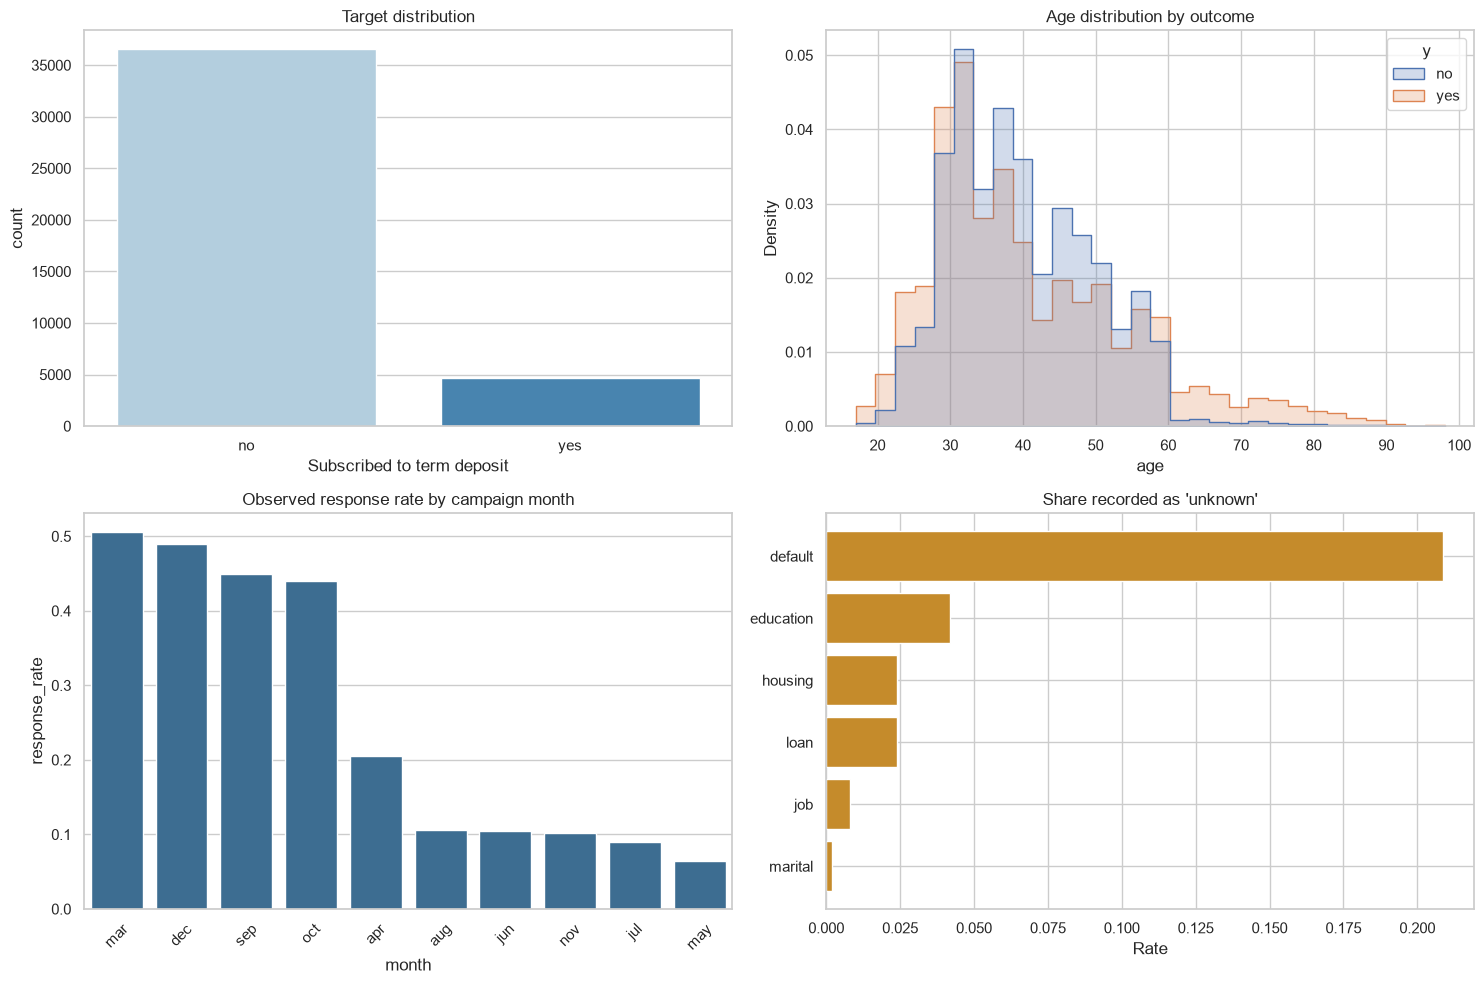

In [41]:
# EDA charts
# how many said yes vs no, age by outcome, response rate by campaign month, and the share of unknown answers per column. 

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.countplot(data=df, x=CONFIG["target"], ax=axes[0, 0], palette="Blues")
axes[0, 0].set_title("Target distribution")
axes[0, 0].set_xlabel("Subscribed to term deposit")

sns.histplot(data=df, x="age", hue=CONFIG["target"], bins=30,
             stat="density", common_norm=False, element="step", ax=axes[0, 1])
axes[0, 1].set_title("Age distribution by outcome")

monthly_rate = response_rate_table(df, "month", minimum_rows=1).reset_index()
sns.barplot(data=monthly_rate, x="month", y="response_rate", ax=axes[1, 0], color="#2f6f9f")
axes[1, 0].set_title("Observed response rate by campaign month")
axes[1, 0].tick_params(axis="x", rotation=45)

unknown_rates = quality_report.query("unknown_count > 0").sort_values("unknown_rate")
axes[1, 1].barh(unknown_rates.index, unknown_rates["unknown_rate"], color="#c58b2b")
axes[1, 1].set_title("Share recorded as 'unknown'")
axes[1, 1].set_xlabel("Rate")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_overview.png", dpi=160, bbox_inches="tight")
plt.show()

In [42]:
# Leakage audit: every column that would not be known before the call 
leakage_audit = pd.DataFrame({
    "feature": ["duration"],
    "available_before_call": [False],
    "reason": ["Current call duration is only known after the call ends."],
    "decision": ["Exclude from the pre-call model"],
})
leakage_audit

,feature,available_before_call,reason,decision
0,duration,False,Current call duration is only known after the ...,Exclude from the pre-call model


In [43]:
#  Building the features and separate X and y
#  two small features were added, previously_contacted (pdays is not 999) and
#   total_contacts (campaign plus previous). Then I split the table into X (inputs) and
#   y (the target), dropping the target columns and duration.

def build_features(frame: pd.DataFrame) -> pd.DataFrame:
    featured = frame.copy()
    featured["previously_contacted"] = (featured["pdays"] != 999).astype(int)
    featured["total_contacts"] = featured["campaign"] + featured["previous"]
    return featured


model_df = build_features(df)

columns_to_drop = [CONFIG["target"], "target"] + CONFIG["leakage_columns"]
X = model_df.drop(columns=columns_to_drop)
y = model_df["target"]

print("Model matrix:", X.shape)
print("Leakage columns removed:", CONFIG["leakage_columns"])

Model matrix: (41176, 21)
Leakage columns removed: ['duration']


In [44]:
# Train, validation and test split
# 0% train, 20% validation and 20% test, so stratify keeps the same yes rate in every part.
# I will choose the model on validation, and the test only tells me how it performs.

X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X,
    y,
    test_size=CONFIG["test_size"],
    random_state=CONFIG["random_state"],
    stratify=y,
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid,
    y_train_valid,
    test_size=CONFIG["validation_size"],
    random_state=CONFIG["random_state"],
    stratify=y_train_valid,
)

split_report = pd.DataFrame({
    "rows": [len(X_train), len(X_valid), len(X_test)],
    "positive_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
}, index=["train", "validation", "test"])
split_report

,rows,positive_rate
train,24705,0.113
validation,8235,0.113
test,8236,0.113


In [45]:
# Preprocessing pipeline and the two selected candidate models
#   numbers get median imputation and scaling,
#   text columns get most-frequent imputation and one-hot encoding. Then I set up two
#   candidate models, logistic regression and random forest, both with class_weight balanced.
#   putting the preprocessing inside a Pipeline means it is fitted only on training data, which
#   avoids another kind of leakage. class_weight balanced is how the we handles
#   the 11% yes rate. I did not add SMOTE or tuning because I want to change only one
#   thing.

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

candidate_models = {
    "logistic_regression": LogisticRegression(
        random_state=CONFIG["random_state"],
        **PARAMS["logistic_regression"],
    ),
    "random_forest": RandomForestClassifier(
        random_state=CONFIG["random_state"],
        **PARAMS["random_forest"],
    ),
}

pipelines = {
    name: Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model),
    ])
    for name, model in candidate_models.items()
}

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 11
Categorical features: 10


In [46]:
# Now Training both models and comparing on validation
# Here we train each model on the training set and score it on the validation
# set with ROC AUC, average precision, precision, recall and F1. I rank them in validation_results.
# I rank by average precision because with so few yes answers it describes how good the ranking is
# better than accuracy. A VIP list only cares about the top of the ranking, so this metric also fits my new assumption.

def probability_metrics(y_true, probabilities, threshold=0.50):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(y_true, probabilities),
        "precision_at_0.5": precision_score(y_true, predictions, zero_division=0),
        "recall_at_0.5": recall_score(y_true, predictions, zero_division=0),
        "f1_at_0.5": f1_score(y_true, predictions, zero_division=0),
    }


validation_rows = []
fitted_candidates = {}

for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    probabilities = pipeline.predict_proba(X_valid)[:, 1]
    validation_rows.append({
        "model": name,
        **probability_metrics(y_valid, probabilities),
    })
    fitted_candidates[name] = pipeline

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values(CONFIG["selection_metric"], ascending=False)
    .reset_index(drop=True)
)
validation_results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
validation_results

Training logistic_regression...
Training random_forest...


,model,roc_auc,average_precision,precision_at_0.5,recall_at_0.5,f1_at_0.5
0,random_forest,0.808,0.463,0.420,0.606,0.496
1,logistic_regression,0.802,0.447,0.364,0.629,0.461


In [47]:
# Now we Pick the best model and test it once
# I take the best model from validation, train it again on train plus validation, and score the untouched test set.
# The scores here use 0.5 as a default cut-off and are
# only a reference. The real decision comes in the next cell.

best_model_name = validation_results.loc[0, "model"]
final_pipeline = clone(pipelines[best_model_name])
final_pipeline.fit(X_train_valid, y_train_valid)

test_probabilities = final_pipeline.predict_proba(X_test)[:, 1]
test_metrics_default = probability_metrics(y_test, test_probabilities)

print("Selected model:", best_model_name)
pd.Series(test_metrics_default, name="test_value").to_frame()

Selected model: random_forest


,test_value
roc_auc,0.814
average_precision,0.490
precision_at_0.5,0.436
recall_at_0.5,0.633
f1_at_0.5,0.516


In [48]:
# The core of my VIP assumption
# I did not use 0.5, capacity_decision takes the score that sits at the
# top 5% of customers, and I contact everyone at or above it. Then I measure precision, recall and lift at that size.
# So the business limit decides the threshold, not the model. With a capacity
# of 0.05 the threshold becomes high, so the VIP list holds only the most likely
# subscribers. Because the list is small, recall is capped: I can never reach more
# than roughly the list size divided by the number of subscribers. So I judge it
# mainly by precision and lift. This is the cell that changes when I change CONFIG.

def capacity_decision(probabilities: np.ndarray, capacity_share: float):
    threshold = float(np.quantile(probabilities, 1 - capacity_share))
    decisions = (probabilities >= threshold).astype(int)
    return threshold, decisions


capacity_threshold, contact_flag = capacity_decision(
    test_probabilities, CONFIG["contact_capacity"]
)

base_rate = y_test.mean()
contacted_precision = precision_score(y_test, contact_flag, zero_division=0)
contacted_recall = recall_score(y_test, contact_flag, zero_division=0)

capacity_metrics = {
    "threshold": capacity_threshold,
    "contact_rate": contact_flag.mean(),
    "precision_at_capacity": contacted_precision,
    "recall_at_capacity": contacted_recall,
    "lift_at_capacity": contacted_precision / base_rate,
}

pd.Series(capacity_metrics, name="test_value").to_frame()

,test_value
threshold,0.824
contact_rate,0.050
precision_at_capacity,0.638
recall_at_capacity,0.283
lift_at_capacity,5.665


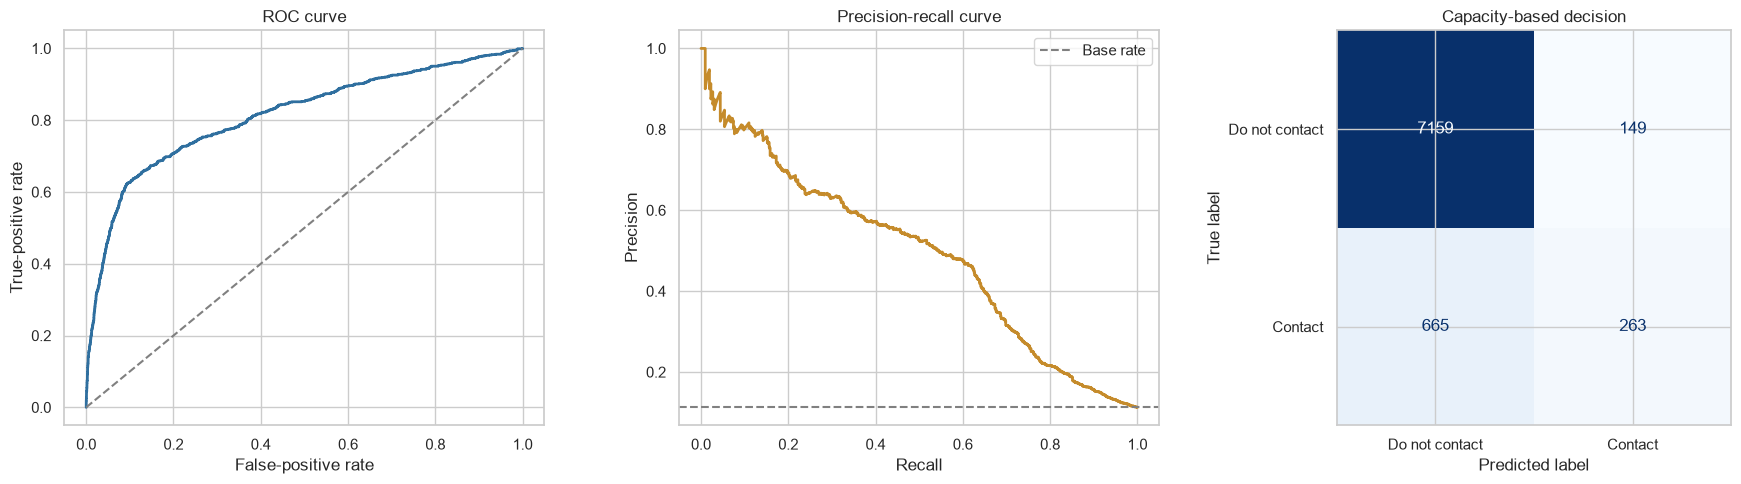

              precision    recall  f1-score   support

          no       0.92      0.98      0.95      7308
         yes       0.64      0.28      0.39       928

    accuracy                           0.90      8236
   macro avg       0.78      0.63      0.67      8236
weighted avg       0.88      0.90      0.88      8236



In [49]:
# Evaluation charts
# the ROC curve, the precision-recall curve and the confusion matrix for the list I chose.

fpr, tpr, _ = roc_curve(y_test, test_probabilities)
pr_precision, pr_recall, _ = precision_recall_curve(y_test, test_probabilities)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(fpr, tpr, color="#2f6f9f", linewidth=2)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[0].set(title="ROC curve", xlabel="False-positive rate", ylabel="True-positive rate")

axes[1].plot(pr_recall, pr_precision, color="#c58b2b", linewidth=2)
axes[1].axhline(y_test.mean(), linestyle="--", color="grey", label="Base rate")
axes[1].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")
axes[1].legend()

ConfusionMatrixDisplay.from_predictions(
    y_test,
    contact_flag,
    display_labels=["Do not contact", "Contact"],
    cmap="Blues",
    colorbar=False,
    ax=axes[2],
)
axes[2].set_title("Capacity-based decision")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()

print(classification_report(y_test, contact_flag, target_names=["no", "yes"]))

In [50]:
# Looking at the errors, score by score
scored_test = X_test.copy()
scored_test["actual"] = y_test.values
scored_test["probability"] = test_probabilities
scored_test["contact_flag"] = contact_flag
scored_test["error_type"] = np.select(
    [
        (scored_test["actual"] == 1) & (scored_test["contact_flag"] == 1),
        (scored_test["actual"] == 0) & (scored_test["contact_flag"] == 0),
        (scored_test["actual"] == 0) & (scored_test["contact_flag"] == 1),
        (scored_test["actual"] == 1) & (scored_test["contact_flag"] == 0),
    ],
    ["true_positive", "true_negative", "false_positive", "false_negative"],
    default="unclassified",
)

error_summary = (
    scored_test.groupby("job", observed=True)
    .agg(
        customers=("actual", "size"),
        actual_response_rate=("actual", "mean"),
        contact_rate=("contact_flag", "mean"),
        average_score=("probability", "mean"),
        false_negatives=("error_type", lambda values: (values == "false_negative").sum()),
    )
    .sort_values("false_negatives", ascending=False)
)
error_summary

,customers,actual_response_rate,contact_rate,average_score,false_negatives
job,,,,,
admin.,2150,0.132,0.064,0.373,195
technician,1319,0.112,0.050,0.332,107
blue-collar,1813,0.067,0.013,0.276,106
services,786,0.081,0.024,0.295,52
management,584,0.110,0.036,0.332,48
retired,330,0.230,0.161,0.502,44
unemployed,202,0.198,0.074,0.389,29
student,184,0.283,0.207,0.573,29
self-employed,307,0.111,0.055,0.357,23


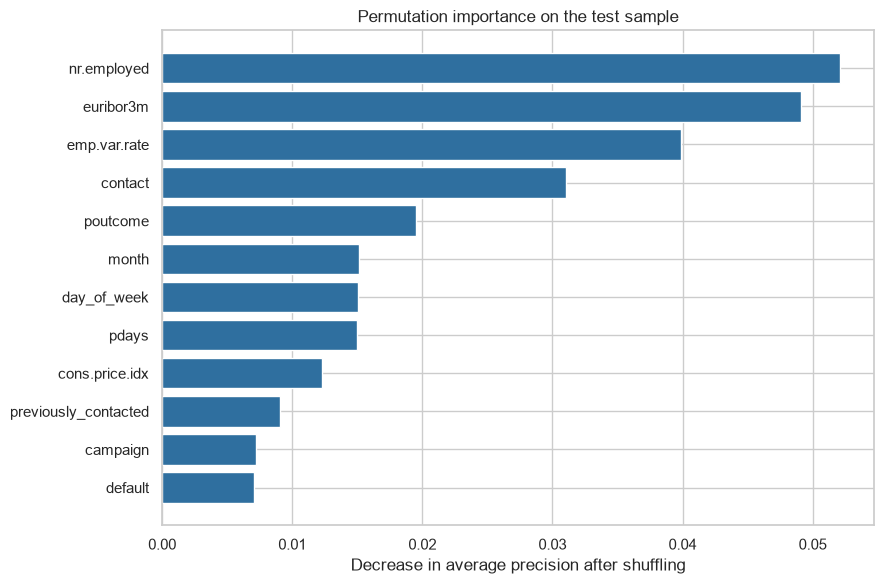

,feature,importance_mean,importance_std
0,nr.employed,0.052,0.007
1,euribor3m,0.049,0.007
2,emp.var.rate,0.040,0.006
3,contact,0.031,0.004
4,poutcome,0.019,0.004
5,month,0.015,0.003
6,day_of_week,0.015,0.002
7,pdays,0.015,0.002
8,cons.price.idx,0.012,0.001
9,previously_contacted,0.009,0.001


In [51]:
# Permutation importance
# here lets shuffle one column at a time and see how much the score drops.
# A column that hurts the score when shuffled is one the model relies on.

importance_sample = X_test.sample(
    n=min(5_000, len(X_test)), random_state=CONFIG["random_state"]
)
importance_target = y_test.loc[importance_sample.index]

importance_result = permutation_importance(
    final_pipeline,
    importance_sample,
    importance_target,
    scoring="average_precision",
    n_repeats=5,
    random_state=CONFIG["random_state"],
    n_jobs=-1,
)

feature_importance = (
    pd.DataFrame({
        "feature": importance_sample.columns,
        "importance_mean": importance_result.importances_mean,
        "importance_std": importance_result.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

top_importance = feature_importance.head(12).sort_values("importance_mean")
plt.figure(figsize=(9, 6))
plt.barh(top_importance["feature"], top_importance["importance_mean"], color="#2f6f9f")
plt.xlabel("Decrease in average precision after shuffling")
plt.title("Permutation importance on the test sample")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()

feature_importance.head(12)

In [52]:
# Now lets Save the model, predictions and the ranked list
# here we save the trained pipeline, the test predictions, the ranked
# outreach list (the VIP list, best first), the importances and a metrics JSON file into the output folder.

outreach_list = (
    scored_test.loc[scored_test["contact_flag"] == 1]
    .sort_values("probability", ascending=False)
    .reset_index()
    .rename(columns={"index": "source_row"})
)

all_metrics = {
    "selected_model": best_model_name,
    "test_default_threshold": test_metrics_default,
    "capacity_decision": capacity_metrics,
    "test_positive_rate": float(y_test.mean()),
}

joblib.dump(final_pipeline, OUTPUT_DIR / "bank_response_pipeline.joblib")
scored_test.to_csv(OUTPUT_DIR / "test_predictions.csv", index=True)
outreach_list.to_csv(OUTPUT_DIR / "ranked_outreach_list.csv", index=False)
feature_importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(all_metrics, file, indent=2)

with open(OUTPUT_DIR / "config.json", "w", encoding="utf-8") as file:
    json.dump(CONFIG, file, indent=2)

serialisable_schema = {**SCHEMA, "allowed_target_values": sorted(SCHEMA["allowed_target_values"])}
with open(OUTPUT_DIR / "schema.json", "w", encoding="utf-8") as file:
    json.dump(serialisable_schema, file, indent=2)

saved_files = sorted(path.name for path in OUTPUT_DIR.iterdir())
print("Saved artefacts:")
for filename in saved_files:
    print(" -", filename)

Saved artefacts:
 - bank_response_pipeline.joblib
 - config.json
 - data_quality_report.csv
 - eda_overview.png
 - feature_importance.csv
 - feature_importance.png
 - metrics.json
 - model_comparison.csv
 - model_evaluation.png
 - ranked_outreach_list.csv
 - schema.json
 - test_predictions.csv


In [53]:
# Reloading the saved model as a sanity check
# Lets load the saved pipeline back from disk and score five rows.

reloaded_pipeline = joblib.load(OUTPUT_DIR / "bank_response_pipeline.joblib")

new_batch = X_test.head(5).copy()
new_batch_scores = reloaded_pipeline.predict_proba(new_batch)[:, 1]

pd.DataFrame({
    "job": new_batch["job"].values,
    "contact": new_batch["contact"].values,
    "subscription_probability": new_batch_scores,
})

,job,contact,subscription_probability
0,services,telephone,0.124
1,student,cellular,0.961
2,self-employed,cellular,0.421
3,blue-collar,cellular,0.513
4,technician,cellular,0.330
